# Mini-Batch Gradient Descent
## Polynomial Regression – Retail Store Profit Prediction

**Project:** Predicting retail store profit using Sales, Quantity, and Discount.

This notebook applies **Mini-Batch Gradient Descent** to Polynomial Regression. It uses the same dataset, target, polynomial degree, train/test split, and preprocessing approach as the previous optimizer notebooks to support a fair comparison.

- **Target:** `Profit`
- **Input features:** `Sales`, `Quantity`, `Discount`
- **Polynomial degree:** 2
- **Mini-batch size:** 32


## 1. Import Libraries

We use NumPy for mathematical operations, Pandas for loading and inspecting the dataset, Matplotlib for plots, and Scikit-learn for splitting and evaluation.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

print("Libraries imported successfully!")


Libraries imported successfully!


## 2. Upload and Load the Dataset

Upload `Sample - Superstore.csv` when prompted. The `cp1252` encoding handles special characters in this dataset.

In [2]:
from google.colab import files

uploaded = files.upload()

df = pd.read_csv("Sample - Superstore.csv", encoding="cp1252")

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

df.head()


Saving Sample - Superstore.csv to Sample - Superstore.csv
Dataset loaded successfully!
Dataset Shape: (9994, 21)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


## 3. Inspect the Dataset

Check the structure, missing values, duplicate rows, and numerical summary before training.

In [3]:
print("Dataset Information:")
df.info()

print("\\nMissing Values:")
print(df.isnull().sum())

print("\\nDuplicate Rows:")
print(df.duplicated().sum())

print("\\nStatistical Summary:")
display(df.describe())


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   object 
 2   Order Date     9994 non-null   object 
 3   Ship Date      9994 non-null   object 
 4   Ship Mode      9994 non-null   object 
 5   Customer ID    9994 non-null   object 
 6   Customer Name  9994 non-null   object 
 7   Segment        9994 non-null   object 
 8   Country        9994 non-null   object 
 9   City           9994 non-null   object 
 10  State          9994 non-null   object 
 11  Postal Code    9994 non-null   int64  
 12  Region         9994 non-null   object 
 13  Product ID     9994 non-null   object 
 14  Category       9994 non-null   object 
 15  Sub-Category   9994 non-null   object 
 16  Product Name   9994 non-null   object 
 17  Sales          9994 non-null   

,Row ID,Postal Code,Sales,Quantity,Discount,Profit
count,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000
mean,4997.500000,55190.379428,229.858001,3.789574,0.156203,28.656896
std,2885.163629,32063.693350,623.245101,2.225110,0.206452,234.260108
min,1.000000,1040.000000,0.444000,1.000000,0.000000,-6599.978000
25%,2499.250000,23223.000000,17.280000,2.000000,0.000000,1.728750
50%,4997.500000,56430.500000,54.490000,3.000000,0.200000,8.666500
75%,7495.750000,90008.000000,209.940000,5.000000,0.200000,29.364000
max,9994.000000,99301.000000,22638.480000,14.000000,0.800000,8399.976000


## 4. Select Features and Target

Use `Sales`, `Quantity`, and `Discount` as input features (`X`) and `Profit` as the target (`y`).

In [4]:
X = df[["Sales", "Quantity", "Discount"]]
y = df["Profit"]

print("Features:", list(X.columns))
print("Target:", y.name)


Features: ['Sales', 'Quantity', 'Discount']
Target: Profit


## 5. Split the Data

Use 80% for training and 20% for testing. `random_state=42` keeps the split reproducible and consistent with the other notebooks.

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))


Training samples: 7995
Testing samples: 1999


## 6. Generate Polynomial Features

Polynomial Regression with degree 2 adds squared and interaction terms to the original features.

In [6]:
poly = PolynomialFeatures(degree=2)

X_train_poly = poly.fit_transform(X_train)
X_test_poly = poly.transform(X_test)

feature_names = poly.get_feature_names_out(["Sales", "Quantity", "Discount"])

print("Original Features:", X_train.shape[1])
print("Polynomial Features:", X_train_poly.shape[1])
print("Polynomial Feature Names:")
print(feature_names)


Original Features: 3
Polynomial Features: 10
Polynomial Feature Names:
['1' 'Sales' 'Quantity' 'Discount' 'Sales^2' 'Sales Quantity'
 'Sales Discount' 'Quantity^2' 'Quantity Discount' 'Discount^2']


## 7. Normalize the Input Features

Calculate the mean and range using training data only, then apply the same values to training and test data. Restore the intercept column to 1.

In [7]:
mean = X_train_poly.mean(axis=0)
range_values = X_train_poly.max(axis=0) - X_train_poly.min(axis=0)
range_values[range_values == 0] = 1

X_train_norm = (X_train_poly - mean) / range_values
X_test_norm = (X_test_poly - mean) / range_values

X_train_norm[:, 0] = 1
X_test_norm[:, 0] = 1

print("Normalization completed successfully!")
print("Training shape:", X_train_norm.shape)
print("Testing shape:", X_test_norm.shape)


Normalization completed successfully!
Training shape: (7995, 10)
Testing shape: (1999, 10)


## 8. Scale the Target Variable

Standardize `Profit` using the training target mean and standard deviation. Predictions will be converted back to the original scale before evaluation.

In [8]:
y_mean = y_train.mean()
y_std = y_train.std()

y_train_scaled = (y_train.to_numpy() - y_mean) / y_std
y_test_scaled = (y_test.to_numpy() - y_mean) / y_std

print("Target scaling completed!")


Target scaling completed!


## 9. Train Polynomial Regression Using Mini-Batch Gradient Descent

**Mini-Batch Gradient Descent** divides the training data into small groups called mini-batches. For each mini-batch, the algorithm calculates the average gradient and updates the weights once.

In each epoch:
1. Shuffle the training examples.
2. Divide them into batches of 32 examples (the final batch may be smaller).
3. Calculate predictions and the average gradient for each batch.
4. Update the weights after each batch.

This approach combines aspects of Batch Gradient Descent and Stochastic Gradient Descent.

In [9]:
# Prepare training arrays
X_mb = X_train_norm
y_mb = y_train_scaled

m, n = X_mb.shape

# Initialize weights
W_mb = np.zeros(n)

# Mini-Batch Gradient Descent settings
learning_rate = 0.01
batch_size = 32
epochs = 200
random_state = 42

rng = np.random.default_rng(random_state)
loss_history_mb = []

# Mini-Batch Gradient Descent training
for epoch in range(epochs):
    indices = rng.permutation(m)
    X_shuffled = X_mb[indices]
    y_shuffled = y_mb[indices]

    for start in range(0, m, batch_size):
        end = start + batch_size

        X_batch = X_shuffled[start:end]
        y_batch = y_shuffled[start:end]

        batch_m = len(X_batch)

        predictions = X_batch @ W_mb
        errors = predictions - y_batch

        gradient = (X_batch.T @ errors) / batch_m
        W_mb = W_mb - learning_rate * gradient

    # Calculate full training loss at the end of each epoch
    epoch_predictions = X_mb @ W_mb
    epoch_loss = np.sum((epoch_predictions - y_mb) ** 2) / (2 * m)
    loss_history_mb.append(epoch_loss)

print("Mini-Batch Gradient Descent Training Completed!")
print("Final Loss:", loss_history_mb[-1])


Mini-Batch Gradient Descent Training Completed!
Final Loss: 0.2591000278163203


## 10. Visualize the Training Loss

The curve shows the average training loss after each epoch. A generally decreasing curve indicates that the model is reducing its training error.

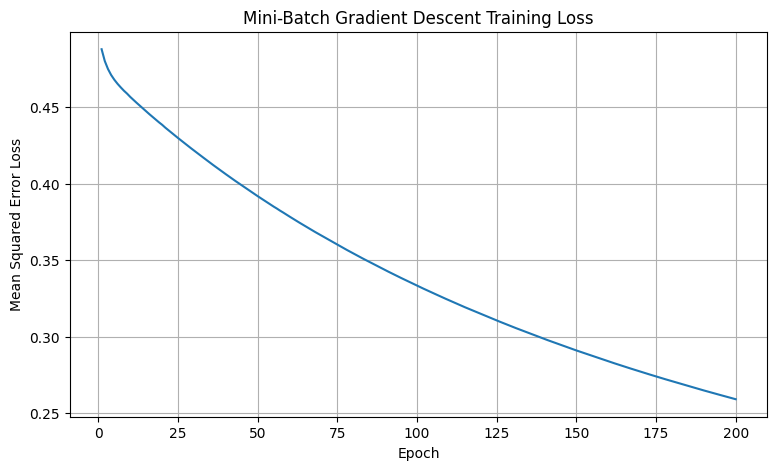

In [10]:
plt.figure(figsize=(9, 5))
plt.plot(range(1, epochs + 1), loss_history_mb)
plt.title("Mini-Batch Gradient Descent Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error Loss")
plt.grid(True)
plt.show()


## 11. Evaluate the Model

Generate predictions for the test set, convert them back to the original profit scale, and calculate MSE, RMSE, MAE, and R².

In [11]:
y_pred_scaled_mb = X_test_norm @ W_mb
y_pred_mb = y_pred_scaled_mb * y_std + y_mean

mse_mb = mean_squared_error(y_test, y_pred_mb)
rmse_mb = np.sqrt(mse_mb)
mae_mb = mean_absolute_error(y_test, y_pred_mb)
r2_mb = r2_score(y_test, y_pred_mb)

print("Mini-Batch Gradient Descent Results")
print("-----------------------------------")
print("MSE:", mse_mb)
print("RMSE:", rmse_mb)
print("MAE:", mae_mb)
print("R2 Score:", r2_mb)


Mini-Batch Gradient Descent Results
-----------------------------------
MSE: 41742.368998522536
RMSE: 204.309493167896
MAE: 56.80183231076374
R2 Score: 0.1390685629608056


## 12. Actual vs. Predicted Profit

This scatter plot compares actual profit values with predicted values. Points closer to the diagonal reference line indicate more accurate predictions.

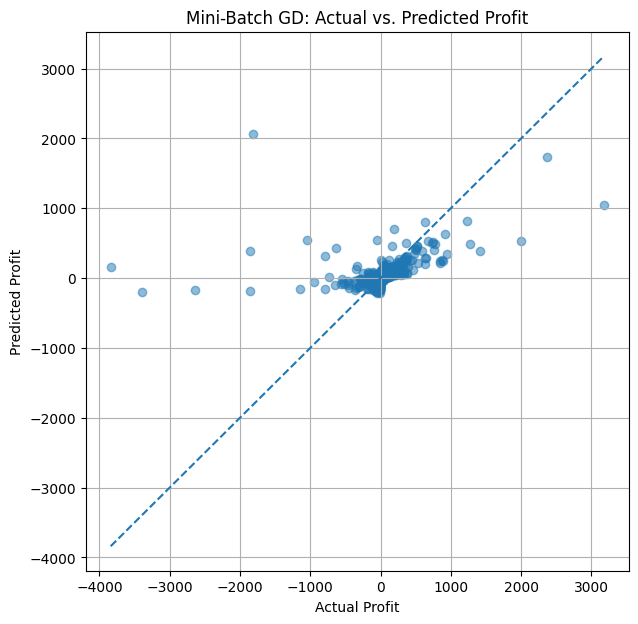

In [12]:
plt.figure(figsize=(7, 7))
plt.scatter(y_test, y_pred_mb, alpha=0.5)

min_value = min(y_test.min(), y_pred_mb.min())
max_value = max(y_test.max(), y_pred_mb.max())
plt.plot([min_value, max_value], [min_value, max_value], linestyle="--")

plt.title("Mini-Batch GD: Actual vs. Predicted Profit")
plt.xlabel("Actual Profit")
plt.ylabel("Predicted Profit")
plt.grid(True)
plt.show()


## 13. Results Summary

Keep these metrics for the final comparison of all five optimization algorithms. Lower RMSE and MAE and a higher R² generally indicate better test-set predictions.

In [13]:
mini_batch_results = pd.DataFrame({
    "Optimizer": ["Mini-Batch Gradient Descent"],
    "Batch Size": [batch_size],
    "Final Training Loss": [loss_history_mb[-1]],
    "MSE": [mse_mb],
    "RMSE": [rmse_mb],
    "MAE": [mae_mb],
    "R2 Score": [r2_mb]
})

display(mini_batch_results)


,Optimizer,Batch Size,Final Training Loss,MSE,RMSE,MAE,R2 Score
0,Mini-Batch Gradient Descent,32,0.2591,41742.368999,204.309493,56.801832,0.139069


## 14. Conclusion

In this notebook, Mini-Batch Gradient Descent was implemented manually using NumPy for a degree-2 Polynomial Regression model that predicts retail store profit.

Unlike Batch Gradient Descent, it updates the weights after processing a small group of examples. Unlike SGD, it uses multiple examples to calculate each update. The loss curve and test metrics help assess its training behavior and predictive performance.

The final metrics will be compared with the other optimizers in the project.